# Practical Assignment 6: Clustering Algorithms

* Name: Yashraj Ghule
* Div: E
* Batch: E1
* Roll no: 316
* PRN: 202401040319

**GITHUB:** https://github.com/Yashraj221B/AIML_TH_LAB/tree/main/C.A/Practical-06-Clustering-Algorithms

## Problem Statement

Implement clustering algorithms on a real-world dataset to identify meaningful groups within the data. Evaluate the quality of the clustering results using appropriate metrics such as the silhouette score, the Davies-Bouldin index, or visual inspection.

The dataset is the Wine dataset that comes with scikit-learn: 178 wines from three grape varieties grown in one region of Italy, with 13 chemical measurements (alcohol, flavanoids, colour intensity, proline and so on). K-Means, Hierarchical (Agglomerative) clustering and DBSCAN are applied and compared. The grape variety is **not** used for clustering. It is only used at the end to check whether the clusters found are meaningful.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

RANDOM_STATE = 42

## 2. Load and inspect the data

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame
X_raw = df.drop(columns="target")
variety = df["target"]          # kept aside, not used for clustering

print(X_raw.shape)
print(X_raw.isnull().sum().sum(), "missing values")
X_raw.describe().round(2).T[["mean", "std", "min", "max"]]

(178, 13)
0 missing values


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


There are no missing values. The features are on very different scales (proline has a standard deviation of 315 while hue has 0.23), so scaling is needed before any distance based clustering.

## 3. Scale the features and reduce to 2D for plotting

K-means, hierarchical clustering and DBSCAN all use distances, so features are standardised first. PCA is used only to draw the clusters in 2D. The clustering itself uses all 13 features.

Variance explained by the 2 components: [0.362 0.192] = 0.554


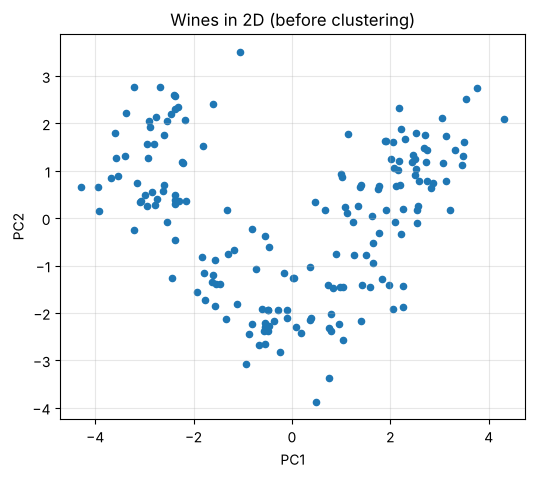

In [3]:
X = StandardScaler().fit_transform(X_raw)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3), "=", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(6, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=20)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wines in 2D (before clustering)")
plt.grid(alpha=0.3)
plt.show()

## 4. Evaluation metrics

* **Silhouette score** (-1 to 1): how close a point is to its own cluster compared with the nearest other cluster. Higher is better.
* **Davies-Bouldin index** (0 and up): average similarity between each cluster and the most similar other cluster. Lower is better.
* **Calinski-Harabasz index:** ratio of between-cluster to within-cluster spread. Higher is better.

A small helper computes all three.

In [4]:
def evaluate(X, labels):
    mask = labels != -1                 # DBSCAN noise points are left out
    if len(set(labels[mask])) < 2:
        return {"Clusters": len(set(labels[mask])), "Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    return {"Clusters": len(set(labels[mask])),
            "Silhouette": silhouette_score(X[mask], labels[mask]),
            "Davies-Bouldin": davies_bouldin_score(X[mask], labels[mask]),
            "Calinski-Harabasz": calinski_harabasz_score(X[mask], labels[mask])}

# 5. K-Means

## Choosing K

The elbow method (WCSS) and the silhouette score are checked for K = 2 to 8.

 K     WCSS  Silhouette  Davies-Bouldin
 2 1658.759       0.259           1.526
 3 1277.928       0.285           1.389
 4 1175.428       0.260           1.797
 5 1109.513       0.202           1.808
 6 1046.002       0.237           1.554
 7  981.595       0.204           1.661
 8  935.201       0.157           1.741


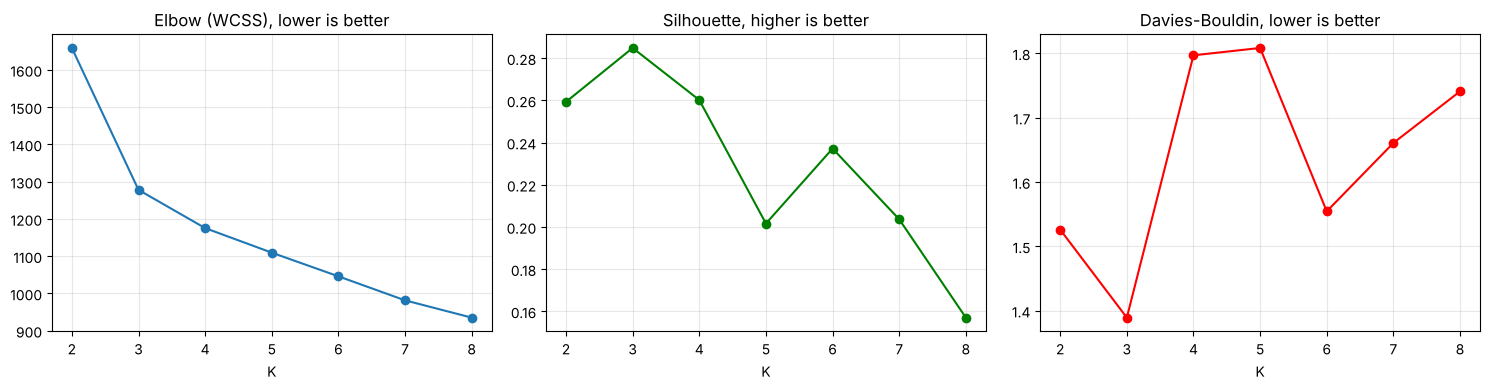

In [5]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    m = evaluate(X, km.labels_)
    rows.append({"K": k, "WCSS": km.inertia_, "Silhouette": m["Silhouette"], "Davies-Bouldin": m["Davies-Bouldin"]})
k_table = pd.DataFrame(rows)
print(k_table.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(k_table["K"], k_table["WCSS"], marker="o"); ax[0].set_title("Elbow (WCSS), lower is better")
ax[1].plot(k_table["K"], k_table["Silhouette"], marker="o", color="green"); ax[1].set_title("Silhouette, higher is better")
ax[2].plot(k_table["K"], k_table["Davies-Bouldin"], marker="o", color="red"); ax[2].set_title("Davies-Bouldin, lower is better")
for a in ax:
    a.set_xlabel("K")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

K = 3 is the best K on all three views. The silhouette score peaks at K = 3 (0.285), the Davies-Bouldin index is lowest at K = 3 (1.389) and the WCSS curve bends there (1,659 at K = 2, 1,278 at K = 3, then only small drops). The scores are not high in absolute terms (silhouette 0.285), which means the groups touch each other a little instead of being perfectly separated.

In [6]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_km = kmeans.labels_
print(pd.Series(labels_km).value_counts().sort_index().to_dict())

{0: 65, 1: 51, 2: 62}


# 6. Hierarchical (Agglomerative) clustering

The dendrogram shows how the wines are merged step by step. Ward linkage merges the pair of clusters that increases the within-cluster variance the least. A long vertical line in the dendrogram that is not cut means the clusters are far apart.

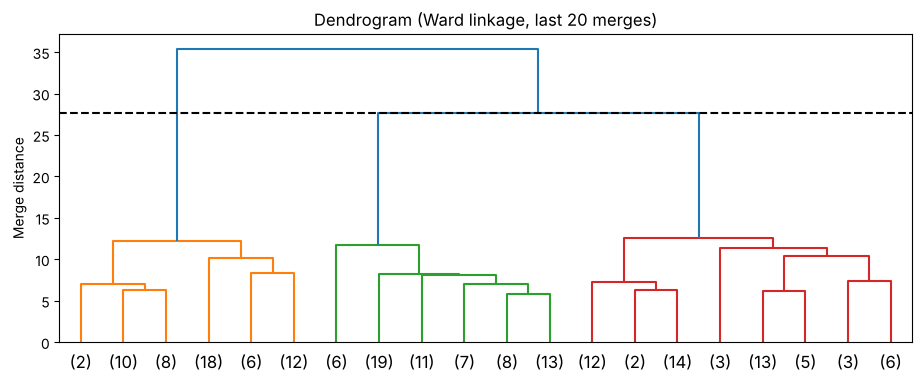

 Linkage  Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz Cluster sizes
    ward         3       0.277           1.419             67.647  [58, 56, 64]
complete         3       0.204           1.896             48.990  [69, 58, 51]
 average         3       0.158           1.030              4.031   [174, 1, 3]
  single         3       0.183           0.911              4.062   [174, 3, 1]


In [7]:
Z = linkage(X, method="ward")
plt.figure(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=20, show_leaf_counts=True, color_threshold=Z[-2, 2] - 0.01)
plt.axhline(Z[-2, 2] - 0.01, color="k", linestyle="--")
plt.title("Dendrogram (Ward linkage, last 20 merges)")
plt.ylabel("Merge distance")
plt.show()

# compare linkage methods for 3 clusters
link_rows = []
for method in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X)
    link_rows.append({"Linkage": method, **evaluate(X, lab), "Cluster sizes": np.bincount(lab).tolist()})
print(pd.DataFrame(link_rows).round(3).to_string(index=False))

Ward linkage gives three groups of similar size (58, 56, 64) and the dendrogram has a clear cut at 3 clusters. Average and single linkage give one huge cluster of 174 wines and two or three tiny ones. Their Davies-Bouldin looks good (1.03 and 0.91) and their Calinski-Harabasz is very low (about 4), but that only shows the metrics can be misled by such useless clusters, so the cluster sizes must be checked as well. Ward is the one used from here on.

In [8]:
labels_hc = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)

# 7. DBSCAN

DBSCAN needs `eps` (neighbourhood radius) and `min_samples`. A common rule is min_samples about 2 x number of features, but with only 178 points that is too strict, so min_samples = 5 is used. `eps` is read from the k-distance plot (distance to the 5th nearest neighbour, sorted), and then a few values near it are tried.

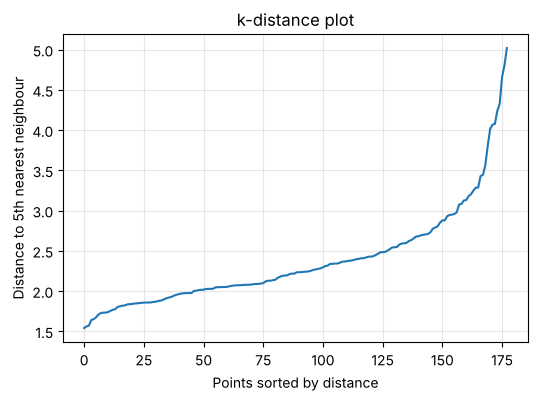

 eps  Noise points  Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz
 1.8           118         7       0.246           1.294             30.672
 2.0            85         5       0.240           1.047             18.751
 2.2            55         2       0.348           1.124             68.391
 2.4            36         2       0.327           1.186             71.934
 2.6            20         1         NaN             NaN                NaN
 2.8            15         1         NaN             NaN                NaN
 3.0            11         1         NaN             NaN                NaN


In [9]:
min_samples = 5
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(6, 4))
plt.plot(kdist)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbour")
plt.title("k-distance plot")
plt.grid(alpha=0.3)
plt.show()

db_rows = []
for eps in [1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    db_rows.append({"eps": eps, "Noise points": int((lab == -1).sum()), **evaluate(X, lab)})
db_table = pd.DataFrame(db_rows)
print(db_table.round(3).to_string(index=False))

DBSCAN is very sensitive to `eps`. With a small eps almost everything is noise (118 of 178 points at 1.8), and with 2.6 or more everything merges into one cluster. The highest silhouette (0.348) is at eps = 2.2, but it finds only 2 clusters and marks 55 wines (31%) as noise, so its silhouette is higher only because the hardest points were left out of the calculation. It is not comparable with the other two on that number.

## 8. Compare the three algorithms

In [10]:
best_eps = 2.2
labels_db = DBSCAN(eps=best_eps, min_samples=min_samples).fit_predict(X)

all_labels = {"K-Means (K=3)": labels_km, "Hierarchical (Ward, 3)": labels_hc, f"DBSCAN (eps={best_eps})": labels_db}
rows = []
for name, lab in all_labels.items():
    m = evaluate(X, lab)
    m["Noise points"] = int((lab == -1).sum())
    m["Adjusted Rand (vs grape variety)"] = adjusted_rand_score(variety, lab)
    rows.append({"Algorithm": name, **m})
comparison = pd.DataFrame(rows).set_index("Algorithm")
comparison.round(3)

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise points,Adjusted Rand (vs grape variety)
Algorithm,,,,,,
K-Means (K=3),3,0.285,1.389,70.940,0,0.897
"Hierarchical (Ward, 3)",3,0.277,1.419,67.647,0,0.790
DBSCAN (eps=2.2),2,0.348,1.124,68.391,55,0.329


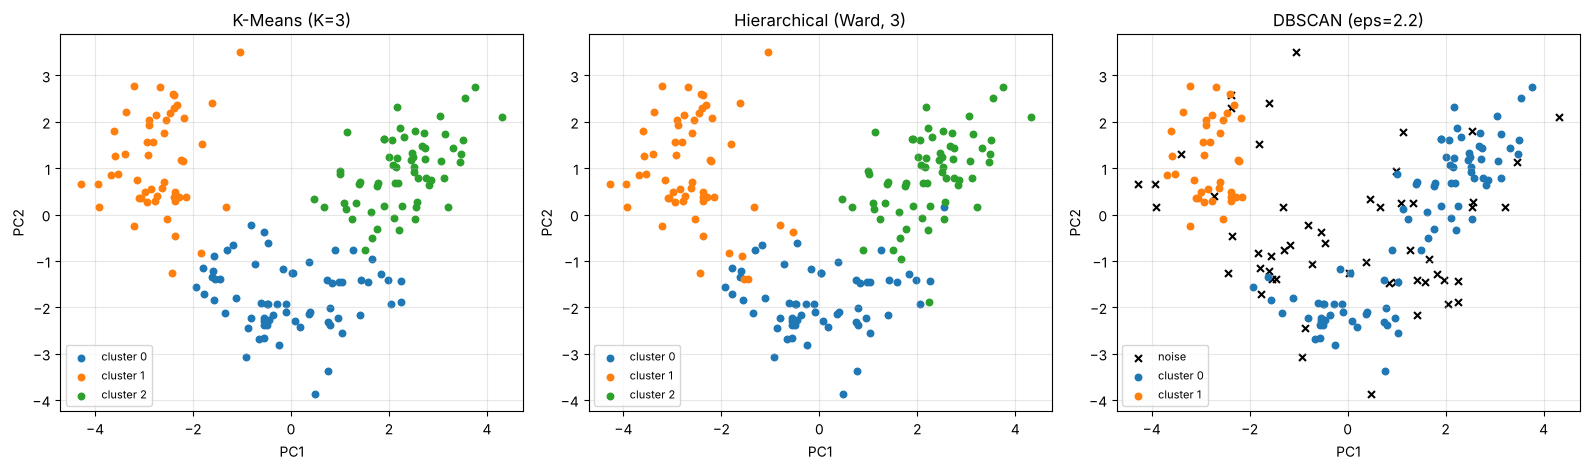

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, (name, lab) in zip(ax, all_labels.items()):
    for c in sorted(set(lab)):
        pts = X_2d[lab == c]
        if c == -1:
            a.scatter(pts[:, 0], pts[:, 1], s=25, color="black", marker="x", label="noise")
        else:
            a.scatter(pts[:, 0], pts[:, 1], s=22, label=f"cluster {c}")
    a.set_title(name)
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

K-Means is the best choice for this data. It has the lowest Davies-Bouldin among the full clusterings that cover every wine (1.389) and the highest Calinski-Harabasz (70.9), and it agrees best with the real grape varieties (adjusted Rand index 0.897, against 0.790 for Ward and 0.329 for DBSCAN). Ward hierarchical is close behind (silhouette 0.277). DBSCAN is not suited here because the wines form three touching groups of similar density instead of separate dense groups with noise between them. In the 2D plot the 3 K-Means clusters look sensible, but the plot only shows 55% of the variance, so some overlap is due to the projection.

## 9. Silhouette plot for the K-Means clusters

Each bar is one wine. Wider and longer bars above the average line mean a well formed cluster.

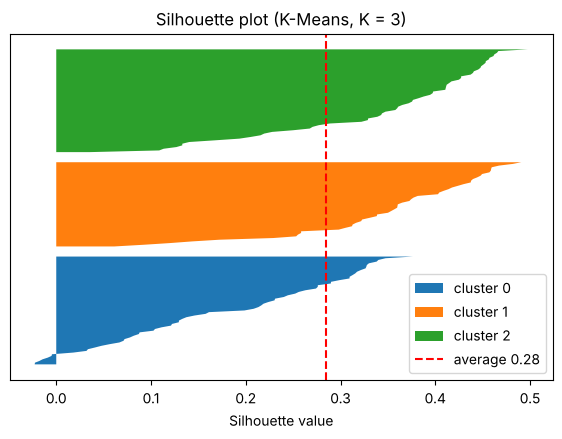

Points with a negative silhouette: 7


In [12]:
from sklearn.metrics import silhouette_samples
sil = silhouette_samples(X, labels_km)
plt.figure(figsize=(7, 4.5))
y0 = 0
for c in range(3):
    vals = np.sort(sil[labels_km == c])
    plt.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, label=f"cluster {c}")
    y0 += len(vals) + 5
plt.axvline(sil.mean(), color="red", linestyle="--", label=f"average {sil.mean():.2f}")
plt.xlabel("Silhouette value")
plt.yticks([])
plt.legend()
plt.title("Silhouette plot (K-Means, K = 3)")
plt.show()
print("Points with a negative silhouette:", int((sil < 0).sum()))

## 10. Does scaling matter? (a check of the preprocessing)

The same K-Means (K = 3) is run on the raw data without scaling.

In [13]:
labels_raw = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X_raw.values)
check = pd.DataFrame([
    {"Data": "Raw (not scaled)", "Silhouette (on scaled data)": silhouette_score(X, labels_raw),
     "Adjusted Rand vs variety": adjusted_rand_score(variety, labels_raw)},
    {"Data": "Scaled", "Silhouette (on scaled data)": silhouette_score(X, labels_km),
     "Adjusted Rand vs variety": adjusted_rand_score(variety, labels_km)},
]).set_index("Data")
print(X_raw.std().sort_values(ascending=False).head(3).round(1).to_dict(), "<- the largest standard deviations")
check.round(3)

{'proline': 314.9, 'magnesium': 14.3, 'alcalinity_of_ash': 3.3} <- the largest standard deviations


,Silhouette (on scaled data),Adjusted Rand vs variety
Data,,
Raw (not scaled),0.108,0.371
Scaled,0.285,0.897


Scaling is a big improvement: the silhouette goes from 0.108 to 0.285 and the agreement with the grape varieties from 0.371 to 0.897. Without it, proline (standard deviation 315) decides almost all the distances and the other 12 features are ignored.

## 11. Profile the clusters

The average of each feature per K-Means cluster (original units) shows what each group is.

In [14]:
profile = X_raw.groupby(labels_km).mean().round(2).T
profile.columns = [f"Cluster {c}" for c in profile.columns]
print("Cluster sizes:", np.bincount(labels_km).tolist())
profile.loc[["alcohol", "flavanoids", "total_phenols", "color_intensity", "proline", "hue", "malic_acid"]]

Cluster sizes: [65, 51, 62]


,Cluster 0,Cluster 1,Cluster 2
alcohol,12.25,13.13,13.68
flavanoids,2.05,0.82,3.00
total_phenols,2.25,1.68,2.85
color_intensity,2.97,7.23,5.45
proline,510.17,619.06,1100.23
hue,1.06,0.69,1.07
malic_acid,1.90,3.31,2.00


In [15]:
# cross-tab with the real grape variety (not used for clustering)
pd.crosstab(labels_km, variety, rownames=["K-Means cluster"], colnames=["Grape variety"])

Grape variety,0,1,2
K-Means cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


The three clusters have clear meanings:

* **Cluster 0 (65 wines):** low alcohol (12.25), low colour intensity (2.97) and low proline (510), the light, mild wines.
* **Cluster 1 (51 wines):** very low flavanoids (0.82), the strongest colour (7.23), the highest malic acid (3.31) and the lowest hue (0.69).
* **Cluster 2 (62 wines):** high alcohol (13.68), high flavanoids (3.00) and a very high proline (1100), the full-bodied wines.

The cross-tab with the real grape variety (which the clustering never saw) shows that the clusters match the grape varieties almost exactly: 172 of the 178 wines (96.6%) are in the cluster that matches their variety. This is an external check that the clusters are meaningful and not just a result of the metrics.

# 12. Conclusion

K-Means with K = 3 on the scaled features was the best of the three algorithms: silhouette 0.285, Davies-Bouldin 1.389 and an adjusted Rand index of 0.897 against the real grape varieties. Hierarchical clustering with Ward linkage was close, and DBSCAN did not fit this data. The choice of K was supported by three different measures, and scaling the features was shown to matter (adjusted Rand index 0.371 without it).

The silhouette score of 0.285 is only moderate, so the clusters overlap and 7 wines have a negative silhouette (they are probably closer to another cluster). Internal metrics like silhouette can also mislead, as seen with average linkage and DBSCAN, so the cluster sizes, the plots and an external check were used as well.